# AI5707 - Assignment 8: GMM, LDA, K-NN, SVM, DTW (Team 20)
Five classifiers (GMM, LDA, K-NN, SVM, and DTW on the speech digits) on four datasets: first on the raw features, then on the projections onto the top-K PCA directions.
That gives 17 models on raw features + 17 models on PCA features = 34 models. K is the smallest number of components that keeps at least 95% of the training variance.
Everything random comes from one LCG. Each classifier is written from its formula; numpy is used for matrix maths and `np.linalg` (`inv`, `slogdet`, `eigh`) for generic linear algebra.
Hyper-parameters are picked on the dev split, test accuracy is read once. PCA is fitted on train only.

In [1]:
# RUN: put this notebook in the "Assignment 8" folder (the one containing teams/, Datasets/, Data/, SyntheticData/), then
#      pip install numpy matplotlib jupyter  ->  jupyter notebook  ->  open this file  ->  Kernel > Restart & Run All
#      (the experiment cells in section 7 are the slow ones and print progress)
import os, pickle, time
import numpy as np
import matplotlib.pyplot as plt

BASE = "."
SEED = 20
SPEECH_SPLIT = (270, 90, 90)       # utterances per digit: train / dev / test
SPEECH_FRAMES = 20                 # frames after interpolation (20 x 39 = 780 features)
PCA_VARIANCE = 0.95               # K = smallest number of PCA components keeping this share of the training variance
SVM_PER_CLASS = 1500               # SVM training subset per class (kernel matrix is n x n)

# ---------------- LCG: x_{n+1} = (a x_n + c) mod m ----------------
class LCG:
    def __init__(self, seed):
        self.m, self.a, self.c = 2**32, 1664525, 1013904223
        self.state = seed % self.m
        for _ in range(5): self.next()
    def next(self):
        self.state = (self.a * self.state + self.c) % self.m
        return self.state
    def uniform(self):  return self.next() / self.m          # in [0,1)
    def randint(self, n): return int(self.uniform() * n)      # in 0..n-1

def shuffled(n, rng):                                         # Fisher-Yates
    idx = list(range(n))
    for i in range(n - 1, 0, -1):
        j = rng.randint(i + 1)
        idx[i], idx[j] = idx[j], idx[i]
    return np.array(idx)

def class_subsample(y, per_class, C, rng):                    # same subset is reused for raw and PCA runs
    out = []
    for c in range(C):
        idx = np.where(y == c)[0]
        out.append(idx[shuffled(len(idx), rng)[:per_class]])
    return np.concatenate(out)

In [2]:
# RUN: after the setup cell. Small helpers + PCA.
def zscore_fit(X):
    mu, sd = X.mean(0), X.std(0)
    sd[sd < 1e-12] = 1.0                       # constant feature: leave as is
    return mu, sd

def accuracy(y, p):
    return float(np.mean(y == p))

def confusion_matrix(y, p, C):                  # rows = true, columns = predicted
    M = np.zeros((C, C), int)
    for t, q in zip(y, p): M[t, q] += 1
    return M

def logsumexp(A):                               # over axis 1
    m = A.max(1, keepdims=True)
    return (m + np.log(np.exp(A - m).sum(1, keepdims=True)))[:, 0]

# PCA: eigenvectors of the covariance matrix, largest eigenvalue first
def covariance(X):
    Xc = X - X.mean(0)
    return Xc.T @ Xc / (len(X) - 1)

def pca_fit(X):
    mu = X.mean(0)
    Xc = X - mu
    cov = Xc.T @ Xc / (len(X) - 1)
    w, V = np.linalg.eigh(cov)                  # ascending order
    return {"mu": mu, "V": V[:, ::-1], "var": w[::-1]}

def pca_project(X, pca, K):
    return (X - pca["mu"]) @ pca["V"][:, :K]

def choose_k(pca, frac):                        # smallest K whose components keep at least `frac` of the variance
    return int(np.argmax(np.cumsum(pca["var"]) / pca["var"].sum() >= frac)) + 1

def pca_explained(pca, K):                      # fraction of total variance kept by K components
    return pca["var"][:K].sum() / pca["var"].sum()

In [3]:
# RUN: after the helpers. GMM per class, trained with EM; classify with Bayes rule (log prior + log likelihood).
#   N(x|mu,S) = (2pi)^(-d/2) |S|^(-1/2) exp(-1/2 (x-mu)' S^-1 (x-mu))
#   E-step: r_nm = w_m N(x_n|mu_m,S_m) / sum_k w_k N(x_n|mu_k,S_k)
#   M-step: N_m = sum_n r_nm,  w_m = N_m/N,  mu_m = sum_n r_nm x_n / N_m,  S_m = sum_n r_nm (x_n-mu_m)(x_n-mu_m)' / N_m  (+ ridge)
def log_gauss(X, mu, S):
    diff = X - mu
    _, logdet = np.linalg.slogdet(S)
    return -0.5 * (X.shape[1] * np.log(2 * np.pi) + logdet + np.sum((diff @ np.linalg.inv(S)) * diff, 1))

def gmm_fit(X, M, reg, rng, iters=30):
    n, d = X.shape
    cov = covariance(X)
    ridge = reg * np.trace(cov) / d * np.eye(d)                # ridge = reg x average variance
    mu = X[shuffled(n, rng)[:M]].copy()                        # random initial means (LCG)
    S = [cov + ridge for _ in range(M)]
    w = np.ones(M) / M
    prev = -np.inf
    for _ in range(iters):
        logp = np.stack([np.log(w[m]) + log_gauss(X, mu[m], S[m]) for m in range(M)], 1)
        lse = logsumexp(logp)
        R = np.exp(logp - lse[:, None])                        # E-step
        Nk = R.sum(0) + 1e-10                                  # M-step
        w, mu = Nk / n, (R.T @ X) / Nk[:, None]
        for m in range(M):
            diff = X - mu[m]
            S[m] = (R[:, m, None] * diff).T @ diff / Nk[m] + ridge
        if abs(lse.sum() - prev) < 1e-4 * n: break
        prev = lse.sum()
    return w, mu, S

def gmm_loglik(model, X):
    w, mu, S = model
    return logsumexp(np.stack([np.log(w[m]) + log_gauss(X, mu[m], S[m]) for m in range(len(w))], 1))

def gmm_classifier_fit(X, y, C, M, reg):
    models = [gmm_fit(X[y == c], M, reg, LCG(SEED + 100 * c + M)) for c in range(C)]
    return models, np.log(np.array([np.mean(y == c) for c in range(C)]))

def gmm_classifier_predict(clf, X):
    models, logprior = clf
    return np.argmax(np.stack([gmm_loglik(m, X) for m in models], 1) + logprior, 1)

In [4]:
# RUN: after the GMM cell. LDA and K-NN.
# LDA: all classes share one covariance S (pooled within-class).  delta_c(x) = x' S^-1 mu_c - 1/2 mu_c' S^-1 mu_c + log pi_c
def lda_fit(X, y, C, lam):
    n, d = X.shape
    mus = np.array([X[y == c].mean(0) for c in range(C)])
    S = sum((X[y == c] - mus[c]).T @ (X[y == c] - mus[c]) for c in range(C)) / (n - C)
    S = S + lam * np.trace(S) / d * np.eye(d)                  # ridge keeps S invertible
    W = np.linalg.inv(S) @ mus.T                               # columns = S^-1 mu_c
    b = -0.5 * np.sum(mus.T * W, 0) + np.log(np.array([np.mean(y == c) for c in range(C)]))
    return W, b

def lda_predict(model, X):
    return np.argmax(X @ model[0] + model[1], 1)

# K-NN: squared Euclidean distance |a|^2 + |b|^2 - 2 a.b, majority vote of the k nearest, ties -> class of the closest neighbour
def vote(lab, k, C):
    score = np.zeros((len(lab), C))
    for c in range(C):
        hit = lab == c
        first = np.where(hit.any(1), hit.argmax(1), k)
        score[:, c] = hit.sum(1) * (k + 1) - first
    return score.argmax(1)

def knn_from_distances(D, ytr, ks, C):                         # D: (queries, train) distance matrix
    lab = ytr[np.argsort(D, axis=1)[:, :max(ks)]]
    return {k: vote(lab[:, :k], k, C) for k in ks}

def knn_predict(Xtr, ytr, Xq, ks, C, chunk=400):
    out = {k: np.empty(len(Xq), int) for k in ks}
    tr_sq = np.sum(Xtr ** 2, 1)
    for s in range(0, len(Xq), chunk):
        Q = Xq[s:s + chunk]
        D = np.sum(Q ** 2, 1)[:, None] + tr_sq[None, :] - 2 * Q @ Xtr.T
        for k, p in knn_from_distances(D, ytr, ks, C).items(): out[k][s:s + len(Q)] = p
    return out

In [5]:
# RUN: after the LDA/K-NN cell. SVM: soft-margin dual solved with SMO, kernels linear / RBF, one-vs-one voting.
#   min 1/2 a'Qa - 1'a   s.t. 0 <= a_i <= C, sum a_i y_i = 0,   Q_ij = y_i y_j K(x_i,x_j),   f(x) = sum a_i y_i K(x_i,x) + b
#   each step picks the most violating pair (i,j) and solves the 2-variable problem exactly (clipped to the box).
def kernel(A, B, kind, gamma):
    if kind == "linear": return A @ B.T
    d2 = np.sum(A ** 2, 1)[:, None] + np.sum(B ** 2, 1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * np.maximum(d2, 0))                  # RBF: exp(-gamma |a-b|^2)

def smo(K, y, C, tol=1e-3, max_iter=100000):
    n = len(y); a = np.zeros(n); G = -np.ones(n)               # G = Q a - 1
    for it in range(max_iter):
        yG = -y * G
        up  = ((y > 0) & (a < C)) | ((y < 0) & (a > 0))
        low = ((y > 0) & (a > 0)) | ((y < 0) & (a < C))
        i = int(np.argmax(np.where(up, yG, -np.inf)))
        j = int(np.argmin(np.where(low, yG, np.inf)))
        if yG[i] - yG[j] < tol: break                          # KKT satisfied
        ai, aj = a[i], a[j]
        if y[i] != y[j]:
            quad = max(K[i, i] + K[j, j] + 2 * y[i] * y[j] * K[i, j], 1e-12)
            delta, diff = (-G[i] - G[j]) / quad, a[i] - a[j]
            a[i] += delta; a[j] += delta
            if diff > 0:
                if a[j] < 0: a[j], a[i] = 0.0, diff
                if a[i] > C: a[i], a[j] = C, C - diff
            else:
                if a[i] < 0: a[i], a[j] = 0.0, -diff
                if a[j] > C: a[j], a[i] = C, C + diff
        else:
            quad = max(K[i, i] + K[j, j] - 2 * y[i] * y[j] * K[i, j], 1e-12)
            delta, s = (G[i] - G[j]) / quad, a[i] + a[j]
            a[i] -= delta; a[j] += delta
            if s > C:
                if a[i] > C: a[i], a[j] = C, s - C
                if a[j] > C: a[j], a[i] = C, s - C
            else:
                if a[j] < 0: a[j], a[i] = 0.0, s
                if a[i] < 0: a[i], a[j] = 0.0, s
        G += y * y[i] * K[:, i] * (a[i] - ai) + y * y[j] * K[:, j] * (a[j] - aj)
    free = (a > 0) & (a < C)
    if free.any(): b = np.mean(-y[free] * G[free])
    else:
        yG = -y * G
        up  = ((y > 0) & (a < C)) | ((y < 0) & (a > 0)); low = ((y > 0) & (a > 0)) | ((y < 0) & (a < C))
        b = 0.5 * (yG[up].max() + yG[low].min())
    return a, b, it + 1 < max_iter

def svm_fit(X, y, C, kind, gamma, Cval):
    machines = {}
    for p in range(C):
        for q in range(p + 1, C):
            idx = np.where((y == p) | (y == q))[0]
            yy = np.where(y[idx] == p, 1.0, -1.0)
            a, b, ok = smo(kernel(X[idx], X[idx], kind, gamma), yy, Cval)
            sv = a > 0
            machines[(p, q)] = (X[idx][sv], (a * yy)[sv], b, ok)
    return machines

def svm_predict(machines, X, C, kind, gamma):
    votes, margin = np.zeros((len(X), C)), np.zeros((len(X), C))
    for (p, q), (Xsv, coef, b, _) in machines.items():
        f = kernel(X, Xsv, kind, gamma) @ coef + b
        votes[f > 0, p] += 1; votes[f <= 0, q] += 1
        margin[:, p] += f;    margin[:, q] -= f
    return np.argmax(votes + 1e-6 * margin, 1)

In [6]:
# RUN: after the SVM cell. DTW:  D(i,j) = c(i,j) + min(D(i-1,j-1), D(i-1,j), D(i,j-1)),  c = Euclidean distance between frames,
#   distance = D(T1,T2) = sum of frame distances along the best warping path (same definition as the team's reference dtw()).
#   dtw_plain is the definition; dtw_matrix evaluates the SAME recursion along anti-diagonals for many reference sequences
#   at once (a plain double loop over 810 x 270 sequence pairs would take hours).
def dtw_plain(a, b):
    D = np.full((len(a) + 1, len(b) + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = np.sqrt(np.sum((a[i - 1] - b[j - 1]) ** 2)) + min(D[i - 1, j - 1], D[i - 1, j], D[i, j - 1])
    return D[-1, -1]

def dtw_matrix(queries, refs, groups=((0, 110), (110, 150), (150, 10**9))):
    lens = np.array([len(r) for r in refs]); out = np.empty((len(queries), len(refs)))
    for lo, hi in groups:                                       # references of similar length are processed together
        mem = np.where((lens > lo) & (lens <= hi))[0]
        if len(mem) == 0: continue
        L, R, Tm = lens[mem], len(mem), int(lens[mem].max())
        P = np.zeros((R, Tm, refs[0].shape[1]))
        for r, m in enumerate(mem): P[r, :L[r]] = refs[m]
        Psq = np.sum(P ** 2, 2)
        for qi, q in enumerate(queries):
            T1 = len(q)
            cost = np.sqrt(np.maximum(Psq[:, :, None] + np.sum(q ** 2, 1)[None, None, :] - 2 * P @ q.T, 0))   # (R, Tm, T1)
            d2 = np.full((R, T1 + 1), np.inf); d2[:, 0] = 0.0   # anti-diagonal s-2
            d1 = np.full((R, T1 + 1), np.inf)                    # anti-diagonal s-1
            res = np.empty(R)
            for s in range(2, T1 + Tm + 1):
                ii = np.arange(max(1, s - Tm), min(T1, s - 1) + 1); jj = s - ii
                cur = np.full((R, T1 + 1), np.inf)
                cur[:, ii] = cost[:, jj - 1, ii - 1] + np.minimum(np.minimum(d2[:, ii - 1], d1[:, ii - 1]), d1[:, ii])
                d2, d1 = d1, cur
                done = np.where(L + T1 == s)[0]
                res[done] = cur[done, T1]
            out[qi, mem] = res
    return out

In [7]:
# RUN: after the DTW cell. The experiment loop used for EVERY dataset (a new dataset = one loading cell + one run_dataset call).
GMM_MS, GMM_REGS = [1, 2, 3], [1e-2, 1e-1]
LDA_LAMS         = [1e-3, 1e-2, 1e-1, 1.0]
KNN_KS           = [1, 3, 5, 7, 9, 11, 15]
SVM_GRID         = [("linear", None, 1.0), ("rbf", 0.5, 1.0), ("rbf", 0.5, 10.0), ("rbf", 2.0, 1.0), ("rbf", 2.0, 10.0)]   # (kernel, g, C)
RESULTS = {}                                                    # (dataset, classifier, 'raw' or K) -> (dev acc, test acc, settings)

def run_gmm(Xtr, ytr, Xdv, ydv, Xte, yte, C):
    best = None
    for M in GMM_MS:
        for reg in GMM_REGS:
            clf = gmm_classifier_fit(Xtr, ytr, C, M, reg)
            acc = accuracy(ydv, gmm_classifier_predict(clf, Xdv))
            if best is None or acc > best[0]: best = (acc, clf, "M=%d reg=%g" % (M, reg))
    return best[0], accuracy(yte, gmm_classifier_predict(best[1], Xte)), best[2]

def run_lda(Xtr, ytr, Xdv, ydv, Xte, yte, C):
    best = None
    for lam in LDA_LAMS:
        m = lda_fit(Xtr, ytr, C, lam); acc = accuracy(ydv, lda_predict(m, Xdv))
        if best is None or acc > best[0]: best = (acc, m, "lam=%g" % lam)
    return best[0], accuracy(yte, lda_predict(best[1], Xte)), best[2]

def pick_k(pdv, pte, ydv, yte):                                 # choose k on dev, report test
    k = max(pdv, key=lambda k: (accuracy(ydv, pdv[k]), -k))
    return accuracy(ydv, pdv[k]), accuracy(yte, pte[k]), "k=%d" % k

def run_knn(Xtr, ytr, Xdv, ydv, Xte, yte, C):
    return pick_k(knn_predict(Xtr, ytr, Xdv, KNN_KS, C), knn_predict(Xtr, ytr, Xte, KNN_KS, C), ydv, yte)

def run_svm(Xtr, ytr, Xdv, ydv, Xte, yte, C, idx):
    X, y = Xtr[idx], ytr[idx]
    total_var = np.sum(np.var(X, 0))
    best = None
    for kind, g, Cval in SVM_GRID:
        gamma = None if g is None else g / total_var
        m = svm_fit(X, y, C, kind, gamma, Cval)
        acc = accuracy(ydv, svm_predict(m, Xdv, C, kind, gamma))
        if best is None or acc > best[0]: best = (acc, m, kind, gamma, "%s g=%s C=%g" % (kind, g, Cval), all(v[3] for v in m.values()))
    return best[0], accuracy(yte, svm_predict(best[1], Xte, C, best[2], best[3])), best[4] + ("" if best[5] else " (SMO hit iteration cap)")

def run_dtw(seqs_fn, fs, ytr, ydv, yte, C):
    str_, sdv, ste = seqs_fn(fs)
    Ddv, Dte = dtw_matrix(sdv, str_), dtw_matrix(ste, str_)      # sum of frame distances along the best path
    return pick_k(knn_from_distances(Ddv, ytr, KNN_KS, C), knn_from_distances(Dte, ytr, KNN_KS, C), ydv, yte)

PCA_INFO = {}                                                   # dataset -> (K, share of variance kept)

def run_dataset(name, feats, ytr, ydv, yte, C, svm_idx, K, kept, seqs_fn=None):
    """feats('raw' or 'pca') -> (Xtr, Xdv, Xte); seqs_fn(...) -> sequences for DTW (speech only). Trains the classifiers on raw, then on top-K PCA features."""
    PCA_INFO[name] = (K, kept)
    for fs in ["raw", "pca"]:
        Xtr, Xdv, Xte = feats(fs)
        print("\n=== %s | %s features | dim=%d%s" % (name, fs, Xtr.shape[1], "" if fs == "raw" else " | top K=%d PCA components keep %.1f%% of the variance" % (K, 100 * kept)))
        jobs = [("GMM", lambda: run_gmm(Xtr, ytr, Xdv, ydv, Xte, yte, C)), ("LDA", lambda: run_lda(Xtr, ytr, Xdv, ydv, Xte, yte, C)),
                ("KNN", lambda: run_knn(Xtr, ytr, Xdv, ydv, Xte, yte, C)), ("SVM", lambda: run_svm(Xtr, ytr, Xdv, ydv, Xte, yte, C, svm_idx))]
        if seqs_fn is not None: jobs.append(("DTW", lambda: run_dtw(seqs_fn, fs, ytr, ydv, yte, C)))
        for clf, job in jobs:
            t0 = time.time(); RESULTS[(name, clf, fs)] = r = job()
            print("  %-4s dev=%.4f test=%.4f  [%s]  %.0fs" % (clf, r[0], r[1], r[2], time.time() - t0))

def vector_features(Xtr, Xdv, Xte):                             # raw features, or top-K PCA features (PCA fitted on TRAIN only)
    pca = pca_fit(Xtr); K = choose_k(pca, PCA_VARIANCE)
    def feats(fs):
        if fs == "raw": return Xtr, Xdv, Xte
        return pca_project(Xtr, pca, K), pca_project(Xdv, pca, K), pca_project(Xte, pca, K)
    return feats, K, pca_explained(pca, K)

## 7. Datasets - each cell loads one dataset and runs everything on it

In [8]:
# RUN: after section 6. SYNTHETIC: data.pkl holds x (20000 x 16) and y (0/1). No split is supplied -> LCG-shuffled, class-balanced 60/20/20.
d = pickle.load(open(os.path.join(BASE, "SyntheticData", "team20", "data.pkl"), "rb"))
X, y = d["x"], d["y"].astype(int)
rng = LCG(SEED + 55); tr, dv, te = [], [], []
for c in range(2):
    idx = np.where(y == c)[0]; idx = idx[shuffled(len(idx), rng)]; n = len(idx)
    tr.append(idx[:int(.6 * n)]); dv.append(idx[int(.6 * n):int(.8 * n)]); te.append(idx[int(.8 * n):])
tr, dv, te = np.concatenate(tr), np.concatenate(dv), np.concatenate(te)
mu, sd = zscore_fit(X[tr])
Xtr, Xdv, Xte = (X[tr] - mu) / sd, (X[dv] - mu) / sd, (X[te] - mu) / sd
print("SYNTHETIC train/dev/test:", Xtr.shape, Xdv.shape, Xte.shape)
feats, K, kept = vector_features(Xtr, Xdv, Xte)
run_dataset("SYNTHETIC", feats, y[tr], y[dv], y[te], 2, class_subsample(y[tr], SVM_PER_CLASS, 2, LCG(SEED + 77)), K, kept)

SYNTHETIC train/dev/test: (12000, 16) (4000, 16) (4000, 16)

=== SYNTHETIC | raw features | dim=16
  GMM  dev=1.0000 test=0.9995  [M=3 reg=0.01]  3s
  LDA  dev=0.9513 test=0.9460  [lam=0.001]  0s
  KNN  dev=0.9985 test=0.9965  [k=5]  23s
  SVM  dev=0.9972 test=0.9948  [rbf g=2.0 C=1]  12s

=== SYNTHETIC | pca features | dim=14 | top K=14 PCA components keep 96.3% of the variance
  GMM  dev=1.0000 test=0.9988  [M=3 reg=0.01]  2s
  LDA  dev=0.9515 test=0.9470  [lam=0.01]  0s
  KNN  dev=0.9970 test=0.9945  [k=5]  23s
  SVM  dev=0.9935 test=0.9918  [rbf g=2.0 C=1]  18s


In [9]:
# RUN: after section 6. MNIST digits 2, 5, 7 (28x28 PNG -> 784 pixels in [0,1]); the supplied train/dev/test split is kept. Reading ~20k PNGs takes a while.
def load_png_split(split, classes):
    X, y = [], []
    for ci, c in enumerate(classes):
        folder = os.path.join(BASE, "teams", "TEAM_20", split, str(c))
        for f in sorted(os.listdir(folder)):
            if f.lower().endswith(".png"):
                img = plt.imread(os.path.join(folder, f))
                if img.ndim == 3: img = img[:, :, 0]
                X.append(img.reshape(-1)); y.append(ci)
    return np.array(X, dtype=np.float64), np.array(y)
(Xtr, ytr), (Xdv, ydv), (Xte, yte) = [load_png_split(s, [2, 5, 7]) for s in ("train", "dev", "test")]
print("MNIST train/dev/test:", Xtr.shape, Xdv.shape, Xte.shape)
feats, K, kept = vector_features(Xtr, Xdv, Xte)
run_dataset("MNIST", feats, ytr, ydv, yte, 3, class_subsample(ytr, SVM_PER_CLASS, 3, LCG(SEED + 77)), K, kept)

MNIST train/dev/test: (14113, 784) (3531, 784) (2952, 784)

=== MNIST | raw features | dim=784
  GMM  dev=0.9918 test=0.9851  [M=2 reg=0.1]  397s
  LDA  dev=0.9725 test=0.9665  [lam=0.01]  4s
  KNN  dev=0.9907 test=0.9905  [k=3]  25s
  SVM  dev=0.9932 test=0.9878  [rbf g=2.0 C=10]  32s

=== MNIST | pca features | dim=155 | top K=155 PCA components keep 95.0% of the variance
  GMM  dev=0.9943 test=0.9875  [M=2 reg=0.1]  76s
  LDA  dev=0.9680 test=0.9614  [lam=0.01]  1s
  KNN  dev=0.9915 test=0.9898  [k=1]  22s
  SVM  dev=0.9938 test=0.9895  [rbf g=2.0 C=10]  35s


In [10]:
# RUN: after section 6. D2: headerless CSVs, 36 features, labels 0-4 (stored in scientific notation -> rounded to integers). z-score with train statistics.
D2 = os.path.join(BASE, "Datasets", "D2", "team20", "Dataset2")
rd = lambda s: (np.loadtxt(os.path.join(D2, s + "_data.csv"), delimiter=","), np.rint(np.loadtxt(os.path.join(D2, s + "_label.csv"), delimiter=",")).astype(int))
(Xtr, ytr), (Xdv, ydv), (Xte, yte) = rd("train"), rd("val"), rd("test")
mu, sd = zscore_fit(Xtr); Xtr, Xdv, Xte = (Xtr - mu) / sd, (Xdv - mu) / sd, (Xte - mu) / sd
print("D2 train/dev/test:", Xtr.shape, Xdv.shape, Xte.shape)
feats, K, kept = vector_features(Xtr, Xdv, Xte)
run_dataset("D2", feats, ytr, ydv, yte, 5, np.arange(len(ytr)), K, kept)

D2 train/dev/test: (2000, 36) (500, 36) (500, 36)

=== D2 | raw features | dim=36
  GMM  dev=0.5880 test=0.5380  [M=2 reg=0.1]  9s
  LDA  dev=0.5940 test=0.5500  [lam=0.001]  0s
  KNN  dev=0.6260 test=0.5480  [k=11]  0s
  SVM  dev=0.6500 test=0.5860  [rbf g=2.0 C=1]  75s

=== D2 | pca features | dim=30 | top K=30 PCA components keep 95.6% of the variance
  GMM  dev=0.6240 test=0.5780  [M=1 reg=0.1]  8s
  LDA  dev=0.6000 test=0.5580  [lam=0.1]  0s
  KNN  dev=0.6180 test=0.5380  [k=7]  0s
  SVM  dev=0.6500 test=0.6080  [rbf g=2.0 C=1]  72s


In [11]:
# RUN: after section 6. TI digits 7, 8, 9: precomputed 39-dim MFCC frames (CMVN already applied), variable length.
#   ordinary classifiers: interpolate to 20 frames and flatten (780 features);  DTW: original frame sequences.
#   PCA: fitted on pooled TRAIN frames, applied frame by frame (K components per frame -> 20*K features).
digits = [7, 8, 9]
rng = LCG(SEED + 33); parts = {"train": [], "dev": [], "test": []}; labels = {"train": [], "dev": [], "test": []}; saved = {}
for ci, dgt in enumerate(digits):
    z = np.load(os.path.join(BASE, "Data", "ExtractedData", "%d.npz" % dgt), allow_pickle=False)
    seqs = [z["arr_%d" % i] for i in range(450)]                # numeric order
    perm = shuffled(450, rng); a, b, c = SPEECH_SPLIT
    for name, idx in (("train", perm[:a]), ("dev", perm[a:a + b]), ("test", perm[a + b:a + b + c])):
        parts[name] += [seqs[i] for i in idx]; labels[name] += [ci] * len(idx); saved["%d_%s" % (dgt, name)] = idx
np.savez("speech_split_indices.npz", **saved)                   # selected utterance indices (utterance-level split, no speaker ids)
str_, sdv, ste = parts["train"], parts["dev"], parts["test"]
ytr, ydv, yte = np.array(labels["train"]), np.array(labels["dev"]), np.array(labels["test"])
print("SPEECH utterances train/dev/test:", len(str_), len(sdv), len(ste), "| frames per utterance:", min(len(s) for s in str_), "-", max(len(s) for s in str_))

def resample(s, L):                                             # linear interpolation to L frames
    pos = np.arange(L) * (len(s) - 1) / (L - 1); i0 = np.floor(pos).astype(int); i1 = np.minimum(i0 + 1, len(s) - 1); w = (pos - i0)[:, None]
    return (1 - w) * s[i0] + w * s[i1]

frame_pca = pca_fit(np.vstack(str_)); K_sp = choose_k(frame_pca, PCA_VARIANCE)     # PCA on pooled TRAIN frames
def speech_sequences(fs):
    if fs == "raw": return str_, sdv, ste
    return [[pca_project(s, frame_pca, K_sp) for s in S] for S in (str_, sdv, ste)]
def speech_features(fs):
    return [np.array([resample(s, SPEECH_FRAMES).reshape(-1) for s in S]) for S in speech_sequences(fs)]
run_dataset("SPEECH", speech_features, ytr, ydv, yte, 3, class_subsample(ytr, SVM_PER_CLASS, 3, LCG(SEED + 77)), K_sp, pca_explained(frame_pca, K_sp), seqs_fn=speech_sequences)

SPEECH utterances train/dev/test: 810 270 270 | frames per utterance: 65 - 257

=== SPEECH | raw features | dim=780
  GMM  dev=0.9852 test=0.9778  [M=1 reg=0.01]  56s
  LDA  dev=0.9667 test=0.9667  [lam=0.1]  1s
  KNN  dev=0.9926 test=0.9889  [k=1]  0s
  SVM  dev=0.9778 test=0.9593  [linear g=None C=1]  3s
  DTW  dev=1.0000 test=0.9963  [k=1]  378s

=== SPEECH | pca features | dim=640 | top K=32 PCA components keep 95.5% of the variance
  GMM  dev=0.9852 test=0.9778  [M=1 reg=0.1]  13s
  LDA  dev=0.9481 test=0.9481  [lam=0.1]  0s
  KNN  dev=0.9926 test=0.9889  [k=1]  0s
  SVM  dev=0.9778 test=0.9667  [rbf g=0.5 C=10]  1s
  DTW  dev=1.0000 test=0.9963  [k=1]  176s


## 8. Results

In [12]:
# RUN: after the dataset cells (works with whichever datasets have been run).
CLFS = ["GMM", "LDA", "KNN", "SVM", "DTW"]
names = [n for n in ["SYNTHETIC", "MNIST", "D2", "SPEECH"] if any(k[0] == n for k in RESULTS)]
cell = lambda n, c, fs: "%.4f" % RESULTS[(n, c, fs)][1] if (n, c, fs) in RESULTS else "N/A"
print("TABLE 1 - test accuracy, raw features")
print("%-10s" % "dataset" + "".join("%9s" % c for c in CLFS))
for n in names: print("%-10s" % n + "".join("%9s" % cell(n, c, "raw") for c in CLFS))
print("\nTABLE 2 - test accuracy, top-K PCA features (K keeps >= %d%% of the training variance)" % round(100 * PCA_VARIANCE))
print("%-10s%6s%9s" % ("dataset", "K", "var kept") + "".join("%9s" % c for c in CLFS))
for n in names: print("%-10s%6d%8.1f%%" % (n, PCA_INFO[n][0], 100 * PCA_INFO[n][1]) + "".join("%9s" % cell(n, c, "pca") for c in CLFS))
print("\nTABLE 3 - every model: dev accuracy, test accuracy and the setting picked on dev")
for (n, c, fs), r in sorted(RESULTS.items(), key=lambda kv: (names.index(kv[0][0]), CLFS.index(kv[0][1]), kv[0][2])):
    print("%-10s %-4s %-4s dev=%.4f test=%.4f  %s" % (n, c, fs, r[0], r[1], r[2]))
print("\nmodels trained and reported:", len(RESULTS), "(17 raw + 17 PCA expected)")

TABLE 1 - test accuracy, raw features
dataset         GMM      LDA      KNN      SVM      DTW
SYNTHETIC    0.9995   0.9460   0.9965   0.9948      N/A
MNIST        0.9851   0.9665   0.9905   0.9878      N/A
D2           0.5380   0.5500   0.5480   0.5860      N/A
SPEECH       0.9778   0.9667   0.9889   0.9593   0.9963

TABLE 2 - test accuracy, top-K PCA features (K keeps >= 95% of the training variance)
dataset        K var kept      GMM      LDA      KNN      SVM      DTW
SYNTHETIC     14    96.3%   0.9988   0.9470   0.9945   0.9918      N/A
MNIST        155    95.0%   0.9875   0.9614   0.9898   0.9895      N/A
D2            30    95.6%   0.5780   0.5580   0.5380   0.6080      N/A
SPEECH        32    95.5%   0.9778   0.9481   0.9889   0.9667   0.9963

TABLE 3 - every model: dev accuracy, test accuracy and the setting picked on dev
SYNTHETIC  GMM  pca  dev=1.0000 test=0.9988  M=3 reg=0.01
SYNTHETIC  GMM  raw  dev=1.0000 test=0.9995  M=3 reg=0.01
SYNTHETIC  LDA  pca  dev=0.9515 test=0.947

## 9. Observations
Write these after reading the tables: best/worst classifier per dataset and why (class overlap, covariance shape, dimension vs sample count);
what ridge (`reg`, `lam`) the GMM/LDA needed; chosen k for K-NN; linear vs RBF and the SMO cap warnings for the SVM; DTW vs fixed-length classifiers on speech;
how the PCA result compares with the raw result for each classifier, and how much variance the chosen K keeps.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

clfs = ["GMM", "LDA", "KNN", "SVM", "DTW"]
datasets = ["SYNTHETIC", "MNIST", "D2", "SPEECH"]
nan = np.nan

raw = pd.DataFrame(
    [[0.9995, 0.9460, 0.9965, 0.9948, nan],
     [0.9851, 0.9665, 0.9905, 0.9878, nan],
     [0.5380, 0.5500, 0.5480, 0.5860, nan],
     [0.9778, 0.9667, 0.9889, 0.9593, 0.9963]],
    index=datasets, columns=clfs)

pca = pd.DataFrame(
    [[0.9988, 0.9470, 0.9945, 0.9918, nan],
     [0.9875, 0.9614, 0.9898, 0.9895, nan],
     [0.5780, 0.5580, 0.5380, 0.6080, nan],
     [0.9778, 0.9481, 0.9889, 0.9667, 0.9963]],
    index=datasets, columns=clfs)

pca_info = pd.DataFrame({"K": [14, 155, 30, 32],
                         "var_kept": [96.3, 95.0, 95.6, 95.5]}, index=datasets)

# (dataset, classifier, dev_raw, test_raw, dev_pca, test_pca)
full = [
 ("SYNTHETIC","GMM",1.0000,0.9995,1.0000,0.9988),
 ("SYNTHETIC","LDA",0.9513,0.9460,0.9515,0.9470),
 ("SYNTHETIC","KNN",0.9985,0.9965,0.9970,0.9945),
 ("SYNTHETIC","SVM",0.9972,0.9948,0.9935,0.9918),
 ("MNIST","GMM",0.9918,0.9851,0.9943,0.9875),
 ("MNIST","LDA",0.9725,0.9665,0.9680,0.9614),
 ("MNIST","KNN",0.9907,0.9905,0.9915,0.9898),
 ("MNIST","SVM",0.9932,0.9878,0.9938,0.9895),
 ("D2","GMM",0.5880,0.5380,0.6240,0.5780),
 ("D2","LDA",0.5940,0.5500,0.6000,0.5580),
 ("D2","KNN",0.6260,0.5480,0.6180,0.5380),
 ("D2","SVM",0.6500,0.5860,0.6500,0.6080),
 ("SPEECH","GMM",0.9852,0.9778,0.9852,0.9778),
 ("SPEECH","LDA",0.9667,0.9667,0.9481,0.9481),
 ("SPEECH","KNN",0.9926,0.9889,0.9926,0.9889),
 ("SPEECH","SVM",0.9778,0.9593,0.9778,0.9667),
 ("SPEECH","DTW",1.0000,0.9963,1.0000,0.9963),
]
full = pd.DataFrame(full, columns=["dataset","clf","dev_raw","test_raw","dev_pca","test_pca"])

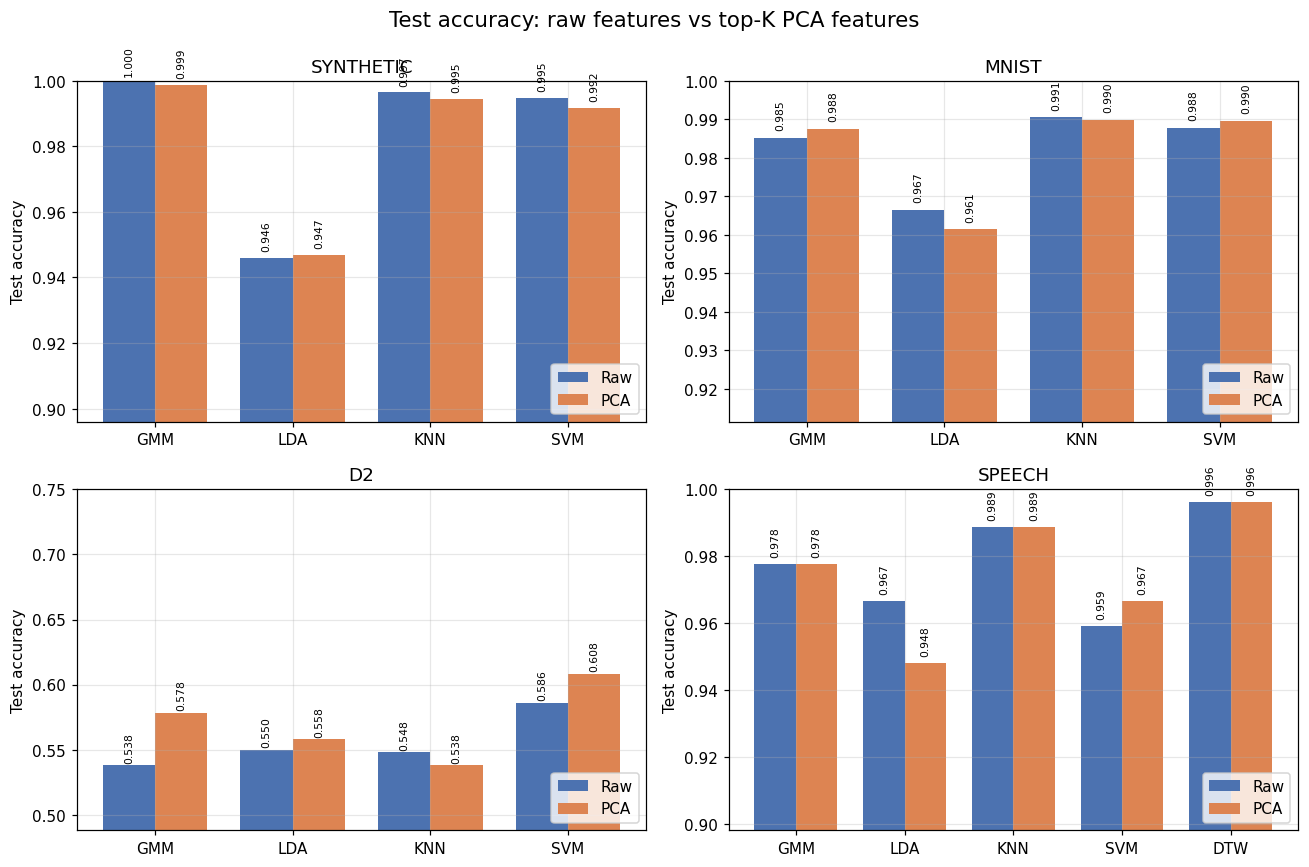

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
w = 0.38
for ax, ds in zip(axes.ravel(), datasets):
    cols = [c for c in clfs if not np.isnan(raw.loc[ds, c])]
    x = np.arange(len(cols))
    r, p = raw.loc[ds, cols].values, pca.loc[ds, cols].values
    b1 = ax.bar(x - w/2, r, w, label="Raw", color="#4C72B0")
    b2 = ax.bar(x + w/2, p, w, label="PCA", color="#DD8452")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.002,
                f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=7, rotation=90)
    lo = min(r.min(), p.min())
    ax.set_ylim(max(0, lo - 0.05), min(1.0, max(r.max(), p.max()) + 0.05) if ds != "D2" else 0.75)
    ax.set_xticks(x); ax.set_xticklabels(cols)
    ax.set_title(ds); ax.set_ylabel("Test accuracy"); ax.legend(loc="lower right")
fig.suptitle("Test accuracy: raw features vs top-K PCA features", fontsize=14)
plt.tight_layout(); plt.show()

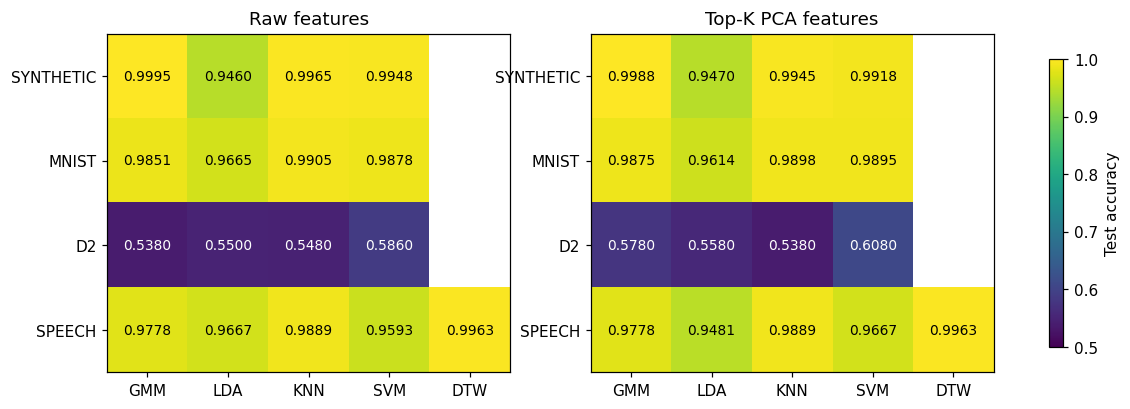

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, df, title in zip(axes, [raw, pca], ["Raw features", "Top-K PCA features"]):
    im = ax.imshow(df.values.astype(float), cmap="viridis", vmin=0.5, vmax=1.0, aspect="auto")
    ax.set_xticks(range(len(clfs))); ax.set_xticklabels(clfs)
    ax.set_yticks(range(len(datasets))); ax.set_yticklabels(datasets)
    ax.grid(False); ax.set_title(title)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]
            ax.text(j, i, "N/A" if np.isnan(v) else f"{v:.4f}", ha="center", va="center",
                    color="white" if (np.isnan(v) or v < 0.8) else "black", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.85, label="Test accuracy")
plt.show()

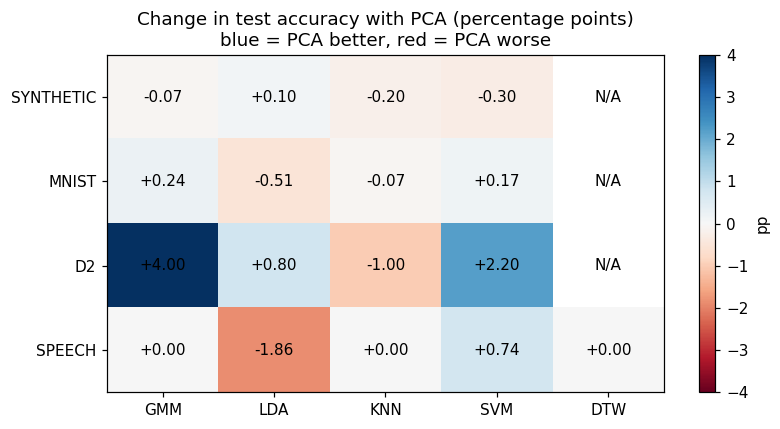

In [17]:
delta = (pca - raw) * 100
fig, ax = plt.subplots(figsize=(7.5, 4))
lim = np.nanmax(np.abs(delta.values))
im = ax.imshow(delta.values.astype(float), cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(clfs))); ax.set_xticklabels(clfs)
ax.set_yticks(range(len(datasets))); ax.set_yticklabels(datasets)
ax.grid(False)
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        v = delta.values[i, j]
        ax.text(j, i, "N/A" if np.isnan(v) else f"{v:+.2f}", ha="center", va="center", fontsize=10)
ax.set_title("Change in test accuracy with PCA (percentage points)\nblue = PCA better, red = PCA worse")
fig.colorbar(im, ax=ax, label="pp")
plt.tight_layout(); plt.show()

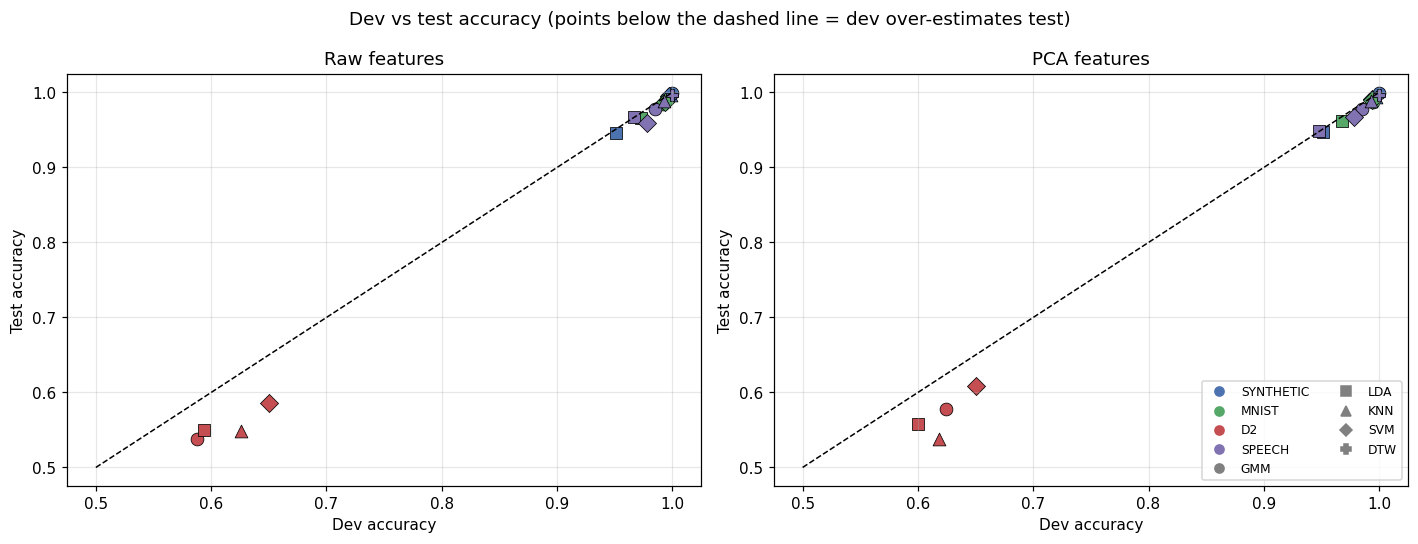

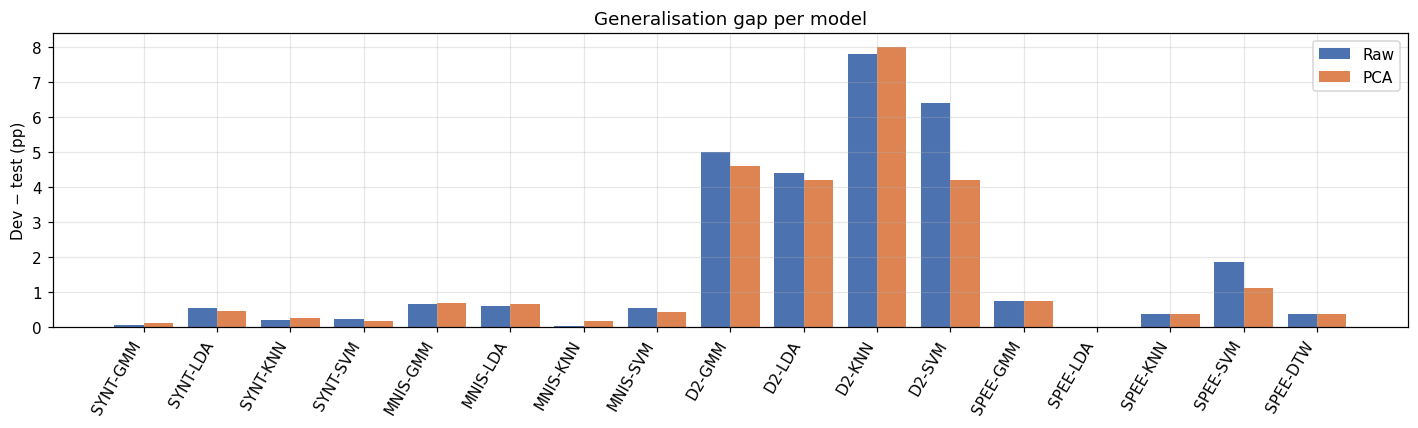

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=False)
colors = {"SYNTHETIC": "#4C72B0", "MNIST": "#55A868", "D2": "#C44E52", "SPEECH": "#8172B2"}
markers = {"GMM": "o", "LDA": "s", "KNN": "^", "SVM": "D", "DTW": "P"}

for ax, suf, title in zip(axes, ["raw", "pca"], ["Raw features", "PCA features"]):
    for _, r in full.iterrows():
        ax.scatter(r[f"dev_{suf}"], r[f"test_{suf}"], c=colors[r.dataset],
                   marker=markers[r.clf], s=70, edgecolor="k", linewidth=0.5)
    ax.plot([0.5, 1.0], [0.5, 1.0], "k--", lw=1)
    ax.set_xlabel("Dev accuracy"); ax.set_ylabel("Test accuracy"); ax.set_title(title)

from matplotlib.lines import Line2D
h = [Line2D([], [], marker="o", color=c, ls="", label=d) for d, c in colors.items()]
h += [Line2D([], [], marker=m, color="gray", ls="", label=k) for k, m in markers.items()]
axes[1].legend(handles=h, loc="lower right", fontsize=8, ncol=2)
fig.suptitle("Dev vs test accuracy (points below the dashed line = dev over-estimates test)")
plt.tight_layout(); plt.show()

# Gap bar chart
full["gap_raw"] = (full.dev_raw - full.test_raw) * 100
full["gap_pca"] = (full.dev_pca - full.test_pca) * 100
lbl = full.dataset.str[:4] + "-" + full.clf
x = np.arange(len(full))
plt.figure(figsize=(13, 4))
plt.bar(x - 0.2, full.gap_raw, 0.4, label="Raw", color="#4C72B0")
plt.bar(x + 0.2, full.gap_pca, 0.4, label="PCA", color="#DD8452")
plt.xticks(x, lbl, rotation=60, ha="right")
plt.ylabel("Dev − test (pp)"); plt.title("Generalisation gap per model"); plt.legend()
plt.tight_layout(); plt.show()

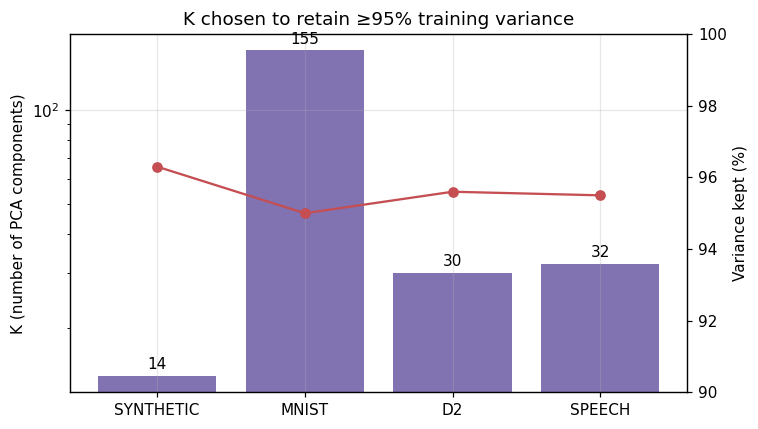

In [19]:
fig, ax1 = plt.subplots(figsize=(7, 4))
bars = ax1.bar(pca_info.index, pca_info.K, color="#8172B2")
ax1.set_ylabel("K (number of PCA components)"); ax1.set_yscale("log")
for b, k in zip(bars, pca_info.K):
    ax1.text(b.get_x() + b.get_width()/2, k * 1.05, str(k), ha="center")
ax2 = ax1.twinx()
ax2.plot(pca_info.index, pca_info.var_kept, "o-", color="#C44E52")
ax2.set_ylim(90, 100); ax2.set_ylabel("Variance kept (%)"); ax2.grid(False)
plt.title("K chosen to retain ≥95% training variance")
plt.tight_layout(); plt.show()

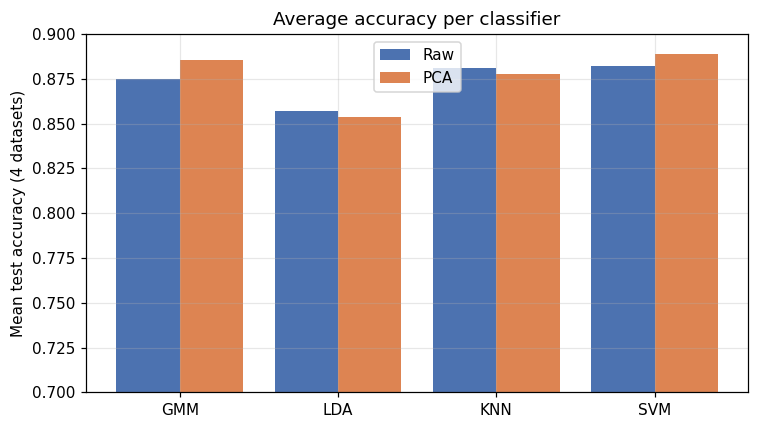

In [20]:
mean_raw = raw[["GMM","LDA","KNN","SVM"]].mean()
mean_pca = pca[["GMM","LDA","KNN","SVM"]].mean()
x = np.arange(4)
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, mean_raw, 0.4, label="Raw", color="#4C72B0")
plt.bar(x + 0.2, mean_pca, 0.4, label="PCA", color="#DD8452")
plt.xticks(x, mean_raw.index); plt.ylim(0.7, 0.9)
plt.ylabel("Mean test accuracy (4 datasets)")
plt.title("Average accuracy per classifier"); plt.legend()
plt.tight_layout(); plt.show()

In [21]:
def gmm_fit_trace(X, M, reg, rng, iters=30):
    """Same as gmm_fit, but returns the per-sample mean log-likelihood at every EM iteration."""
    n, d = X.shape
    cov = covariance(X)
    ridge = reg * np.trace(cov) / d * np.eye(d)
    mu = X[shuffled(n, rng)[:M]].copy()
    S = [cov + ridge for _ in range(M)]
    w = np.ones(M) / M
    hist, prev = [], -np.inf
    for _ in range(iters):
        logp = np.stack([np.log(w[m]) + log_gauss(X, mu[m], S[m]) for m in range(M)], 1)
        lse = logsumexp(logp)
        hist.append(lse.mean())
        R = np.exp(logp - lse[:, None])
        Nk = R.sum(0) + 1e-10
        w, mu = Nk / n, (R.T @ X) / Nk[:, None]
        for m in range(M):
            diff = X - mu[m]
            S[m] = (R[:, m, None] * diff).T @ diff / Nk[m] + ridge
        if abs(lse.sum() - prev) < 1e-4 * n: break
        prev = lse.sum()
    return np.array(hist)

EM_TRACES = {}   # (dataset, class) -> history

def em_curves(name, Xtr, ytr, C, M, reg):
    """Run EM for each class with the same seeds as gmm_classifier_fit and store the curves."""
    for c in range(C):
        EM_TRACES[(name, c)] = gmm_fit_trace(Xtr[ytr == c], M, reg, LCG(SEED + 100 * c + M))
    print(name, "M=%d reg=%g" % (M, reg), "| iterations to stop:",
          [len(EM_TRACES[(name, c)]) for c in range(C)])

In [ ]:
# Rebuild each dataset's TRAIN matrix under new names. Nothing from the earlier cells is overwritten.
EM_TRACES.clear()

# SYNTHETIC: X, y, tr from the SYNTHETIC cell are still intact (mu/sd were overwritten by D2, so recompute)
mu_s, sd_s = zscore_fit(X[tr])
Xs, ys = (X[tr] - mu_s) / sd_s, y[tr]
print("SYNTHETIC", Xs.shape, ys.shape)
em_curves("SYNTHETIC", Xs, ys, 2, M=3, reg=1e-2)

# MNIST: reload the train split only (slow-ish, PNG reading)
Xm, ym = load_png_split("train", [2, 5, 7])
print("MNIST", Xm.shape, ym.shape)
em_curves("MNIST", Xm, ym, 3, M=2, reg=1e-1)

# D2: reload train CSVs and z-score with train statistics, as in the D2 cell
Xd, yd = rd("train")
mu_d, sd_d = zscore_fit(Xd)
Xd = (Xd - mu_d) / sd_d
print("D2", Xd.shape, yd.shape)
em_curves("D2", Xd, yd, 5, M=2, reg=1e-1)

# SPEECH: train features from the SPEECH cell, labels from its `labels` dict
Xsp = speech_features("raw")[0]
ysp = np.array(labels["train"])
print("SPEECH", Xsp.shape, ysp.shape)
em_curves("SPEECH", Xsp, ysp, 3, M=3, reg=1e-1)   # selected model is M=1 (trivial EM), so M=3 is for illustration only

SYNTHETIC (12000, 16) (12000,)
SYNTHETIC M=3 reg=0.01 | iterations to stop: [30, 7]
MNIST (14113, 784) (14113,)
MNIST M=2 reg=0.1 | iterations to stop: [30, 30, 4]
D2 (2000, 36) (2000,)
D2 M=2 reg=0.1 | iterations to stop: [30, 30, 30, 26, 30]
SPEECH (810, 780) (810,)


In [ ]:
names_em = sorted({k[0] for k in EM_TRACES}, key=["SYNTHETIC","MNIST","D2","SPEECH"].index)
fig, axes = plt.subplots(1, len(names_em), figsize=(4.2 * len(names_em), 3.6), squeeze=False)
for ax, nm in zip(axes[0], names_em):
    for (n, c), h in EM_TRACES.items():
        if n == nm:
            ax.plot(range(1, len(h) + 1), h, "o-", ms=3, label="class %d" % c)
    ax.set_title(nm); ax.set_xlabel("EM iteration"); ax.legend(fontsize=8)
axes[0][0].set_ylabel("Mean train log-likelihood per sample")
fig.suptitle("EM convergence of the per-class GMMs", fontsize=13)
plt.tight_layout(); plt.show()